# 02 — Sélection des variables

## Partie A — Screening naïf : qu'est-ce qui n'a pas sa place dans X ?

**Question :** parmi les colonnes de `dataset_v2.csv`, lesquelles ne doivent pas être des prédicteurs (vecteur X) d'un modèle de régression de Q10 ?

**Principe :** une colonne n'entre dans X que si elle remplit trois critères :
1. **Disponible partout** : elle existe en carte mondiale. Sinon, impossible de produire la carte de Q10 pour ORCHIDEE.
2. **Plausible physiquement** : elle peut agir sur Q10 (climat, sol), et n'est pas un artefact de l'échantillonnage.
3. **Exploitable statistiquement** : pas de valeurs manquantes, non constante, non redondante avec une autre variable.

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat** / **Décision**.

In [1]:
# Imports : pandas pour les données, matplotlib pour les graphiques
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Chargement de la version de référence du dataset (une ligne par site)
df = pd.read_csv("../data/dataset_v2.csv")
df.head()

,site,source,study,Q10,n_mesures,lat,lon,MAT_public,MAP_public,pH_public,N515
0,paper_66,paper,paper_47,2.155653,1,-37.422361,144.094194,12.120522,636.457930,5.749557,2431.892349
1,paper_34,paper,paper_25,3.230911,1,14.583333,98.866667,24.521796,1572.758221,5.579726,2371.518618
2,paper_69,paper,paper_49,2.193185,1,21.160000,101.040000,21.166023,1826.576010,5.267783,2658.456495
3,dig_Zhao2021_Xishuangbanna,figure,dig_Zhao2021,2.589000,1,21.617000,101.583000,20.573714,1776.573980,5.152625,2276.136182
4,paper_80,paper,paper_57,2.012824,1,22.166667,106.833333,21.297576,1569.578627,5.924567,1649.934092


### Étape 1 — Rôle de chaque colonne (critère 1)

**Objectif :** écarter les colonnes qui, par nature, ne peuvent pas être des prédicteurs.

**Raisonnement :** pour prédire Q10 en un point quelconque de la planète, le modèle ne peut utiliser que des informations disponibles en ce point, donc des cartes mondiales.

| Colonne | Rôle | En carte mondiale ? | Décision |
|---|---|---|---|
| `site`, `study` | identifiants | non | **exclure** : un modèle qui les utiliserait apprendrait des sites par cœur, sans rien pouvoir prédire ailleurs |
| `source` | métadonnée : base d'origine de la mesure | non | **exclure** : utile pour contrôler des biais de mesure, pas pour prédire |
| `n_mesures` | métadonnée : nombre de mesures agrégées | non | **exclure** : pourra servir de *poids* (un Q10 moyen sur 9 mesures est plus fiable) |
| `Q10` | cible | — | c'est y |
| `lat`, `lon` | coordonnées | oui | à examiner (étape 2) |
| `MAT_public`, `MAP_public`, `pH_public`, `N515` | climat et sol | oui | candidats (étape 3) |

### Étape 2 — Latitude et longitude (critère 2)

**Objectif :** décider si les coordonnées entrent dans X.

**Raisonnement :** elles sont disponibles partout (critère 1 rempli), mais ce ne sont pas des moteurs physiques : la latitude n'agit sur Q10 qu'à travers le climat et le sol, que l'on mesure déjà. Hacopian a exclu la latitude pour cette raison. Le risque est que le modèle apprenne **où se trouvent nos sites** plutôt que **ce qui fait varier Q10**, et qu'il soit perdu dans les régions qui ne sont pas représentées. On regarde donc la répartition géographique des sites.

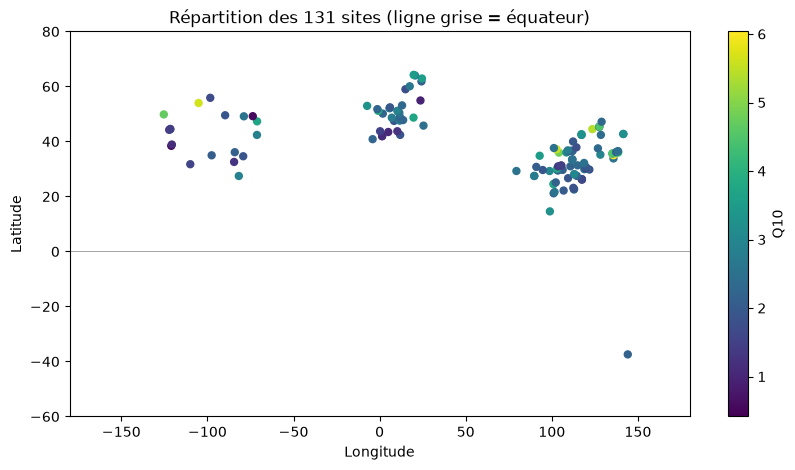

In [3]:
# Carte simple des sites (longitude, latitude), couleur = Q10
plt.figure(figsize=(10, 5))
plt.scatter(df.lon, df.lat, c=df.Q10, s=25)
plt.colorbar(label="Q10")
plt.axhline(0, c="grey", lw=0.5)
plt.xlim(-180, 180); plt.ylim(-60, 80)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Répartition des 131 sites (ligne grise = équateur)")
plt.show()

In [4]:
# Part des sites dans l'hémisphère Nord, en Asie de l'Est (lon 73–146°, lat 18–54°) et en zone tropicale
print(f"Hémisphère Nord : {(df.lat > 0).mean():.0%}")
print(f"Asie de l'Est : {(df.lon.between(73, 146) & df.lat.between(18, 54)).mean():.0%}")
print(f"Zone tropicale (|lat| < 23.5°) : {(df.lat.abs() < 23.5).sum()} sites")

Hémisphère Nord : 99%
Asie de l'Est : 58%
Zone tropicale (|lat| < 23.5°) : 7 sites


In [5]:
# Corrélation entre |latitude| et MAT : la latitude est-elle un simple relais du climat ?
print(f"r = {df.lat.abs().corr(df.MAT_public):.2f}")

r = -0.64


**Constat :** les sites forment trois groupes (Amérique du Nord, Europe, Asie de l'Est). 99 % sont dans l'hémisphère Nord (un seul site au Sud, en Australie), 58 % en Asie de l'Est, et seulement 7 en zone tropicale. Il n'y a aucun site en Afrique ni en Amérique du Sud. La valeur absolue de la latitude est fortement liée à MAT (r = −0.64) : elle n'apporte donc pas d'information physique nouvelle.

**Décision (équipe) : conserver `lat` et `lon` comme candidats pour l'instant.** Leur effet sur Q10 n'est pas direct, mais il existe probablement : les coordonnées peuvent porter des informations qu'aucune autre variable ne mesure (végétation, histoire des sols, communautés microbiennes régionales…). La sélection rigoureuse (LASSO et validation croisée spatiale) dira si elles améliorent vraiment les prédictions.

**Points de vigilance**, issus des constats ci-dessus :
- l'échantillon est très concentré : la validation croisée devra être groupée par zone géographique, sinon l'apport des coordonnées sera surestimé ;
- sur la carte mondiale, les prédictions dans les zones sans aucun site (hémisphère Sud, Afrique, Amérique du Sud) seront à interpréter avec prudence ;
- la part de la prédiction portée par les coordonnées restera figée si le climat change.

### Étape 3 — Contrôles statistiques des candidats (critère 3)

**Objectif :** vérifier que les 6 candidats (coordonnées, climat, sol) sont exploitables.

**Raisonnement :** on vérifie, dans l'ordre : valeurs manquantes et valeurs distinctes, forme des distributions, redondance entre candidats, puis lien avec Q10.

In [6]:
# Variables candidates : coordonnées, climat et sol, toutes disponibles en carte mondiale
X_cols = ["lat", "lon", "MAT_public", "MAP_public", "pH_public", "N515"]

In [7]:
# Nombre de valeurs manquantes et de valeurs distinctes par candidat
pd.DataFrame({"manquantes": df[X_cols].isna().sum(), "distinctes": df[X_cols].nunique()})

,manquantes,distinctes
lat,0,130
lon,0,129
MAT_public,0,131
MAP_public,0,131
pH_public,0,131
N515,0,131


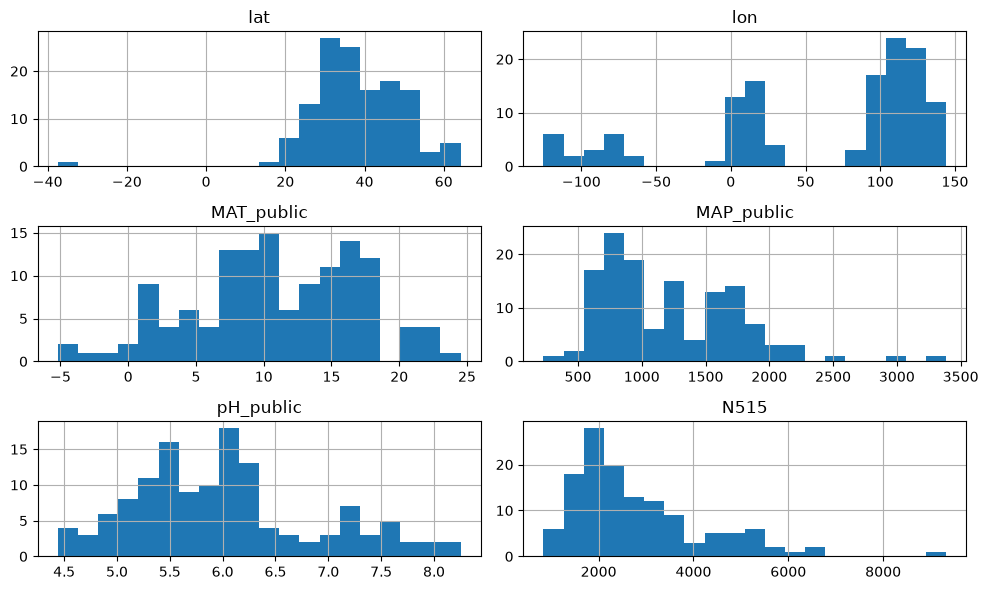

In [8]:
# Distribution de chaque candidat
df[X_cols].hist(bins=20, figsize=(10, 6))
plt.tight_layout(); plt.show()

In [9]:
# Asymétrie des distributions (0 = symétrique ; > 1 = longue queue à droite)
df[X_cols].skew().round(2)

lat          -1.53
lon          -0.94
MAT_public   -0.24
MAP_public    1.00
pH_public     0.65
N515          1.43
dtype: float64

**Constat :** aucune valeur manquante, et presque autant de valeurs distinctes que de sites (quelques sites partagent la même latitude ou la même longitude). MAP et N515 ont une longue queue à droite (asymétrie 1.0 et 1.4) : un passage au logarithme pourra aider les modèles linéaires. C'est une question de transformation, pas d'exclusion, à trancher à l'étape des modèles. `lat` a une queue vers le bas (−1.5), due au seul site de l'hémisphère Sud. La distribution de `lon` a trois paquets (Amérique du Nord, Europe, Asie de l'Est) : elle décrit des régions plus qu'un gradient continu.

In [10]:
# Corrélations entre candidats (Spearman : robuste aux valeurs extrêmes et aux relations non linéaires monotones)
df[X_cols].corr("spearman").round(2)

,lat,lon,MAT_public,MAP_public,pH_public,N515
lat,1.00,-0.43,-0.68,-0.57,-0.02,0.39
lon,-0.43,1.00,0.12,0.27,-0.01,-0.09
MAT_public,-0.68,0.12,1.00,0.47,-0.11,-0.55
MAP_public,-0.57,0.27,0.47,1.00,-0.51,0.14
pH_public,-0.02,-0.01,-0.11,-0.51,1.00,-0.49
N515,0.39,-0.09,-0.55,0.14,-0.49,1.00


**Constat :** la plus forte corrélation entre candidats est de 0.68 en valeur absolue (lat–MAT), sous le seuil usuel de 0.8 à partir duquel deux variables sont jugées redondantes. **Aucun candidat n'est exclu pour redondance.** Ces corrélations moyennes rendront cependant les coefficients d'un modèle linéaire instables, comme le notait déjà Hacopian : c'est un argument pour la régularisation (Ridge, LASSO).

In [11]:
# Corrélation de chaque candidat avec Q10 (Pearson : lien linéaire ; Spearman : lien monotone)
pd.DataFrame({"pearson": df[X_cols].corrwith(df.Q10), "spearman": df[X_cols].corrwith(df.Q10, method="spearman")}).round(2)

,pearson,spearman
lat,0.09,0.09
lon,0.21,0.23
MAT_public,-0.26,-0.30
MAP_public,-0.00,-0.04
pH_public,-0.02,-0.12
N515,0.25,0.35


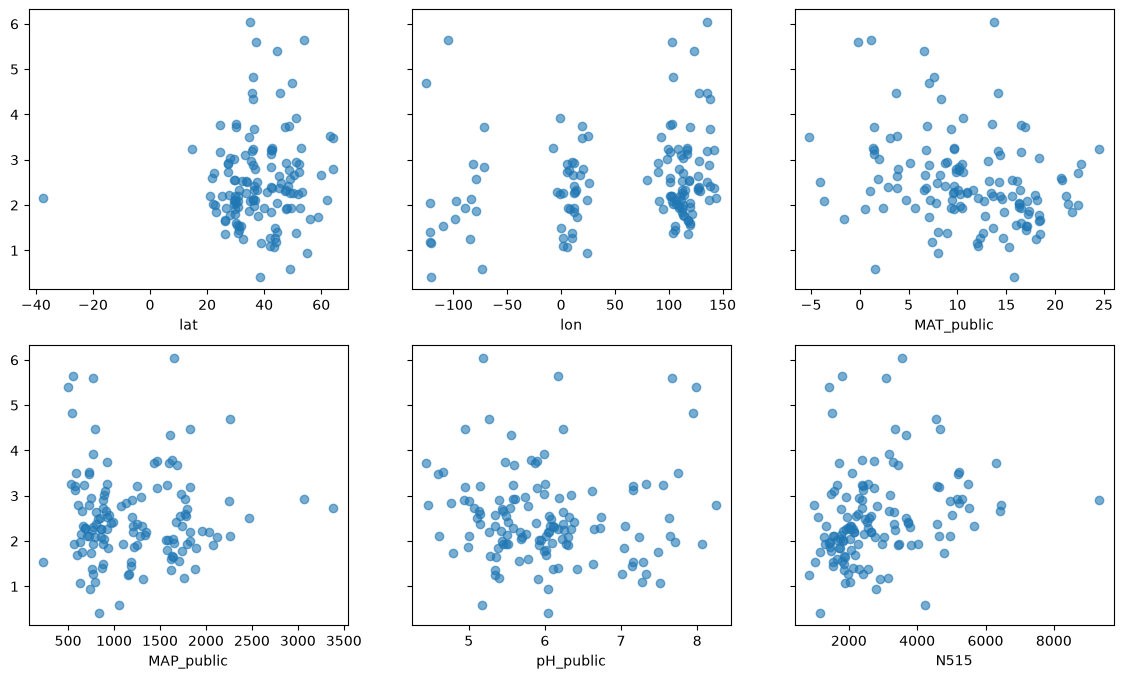

In [12]:
# Q10 en fonction de chaque candidat
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, col in zip(axes.flat, X_cols):
    ax.scatter(df[col], df.Q10, alpha=0.6); ax.set_xlabel(col)
plt.show()

**Constat :** les nuages de points sont très dispersés : même les liens les plus nets sont faibles. MAT (Spearman −0.30) et N515 (+0.35) ont un lien visible avec Q10, `lon` un lien plus faible (+0.23). MAP (−0.04), pH (−0.12) et `lat` (+0.09) n'en ont presque aucun pris isolément. Pour le pH, c'est différent de Hacopian (+0.30) ; nos données ne sont pas les mêmes (sources ajoutées, pas de pondération par R², agrégation par site).

### Étape 4 — Faut-il exclure MAP et pH ?

**Objectif :** vérifier si un lien faible avec Q10 pris isolément suffit à exclure une variable.

**Raisonnement :** une variable peut ne montrer aucun lien seule et en avoir un une fois les autres prises en compte. C'est le cas si son effet est masqué par une variable avec laquelle elle varie (ici, MAP et MAT sont corrélées à 0.47 : les régions humides sont souvent plus chaudes). On compare les coefficients d'une régression linéaire sur variables centrées-réduites, pour qu'ils soient comparables entre variables.

In [13]:
# Import : régression linéaire
from sklearn.linear_model import LinearRegression

In [14]:
# Candidats centrés-réduits (moyenne 0, écart-type 1)
Z = (df[X_cols] - df[X_cols].mean()) / df[X_cols].std()

In [15]:
# Coefficient de MAP seul, puis de MAT et MAP ensemble
print(f"MAP seul : {LinearRegression().fit(Z[['MAP_public']], df.Q10).coef_[0]:.3f}")
print("MAT + MAP :", LinearRegression().fit(Z[["MAT_public", "MAP_public"]], df.Q10).coef_.round(2))

MAP seul : -0.002
MAT + MAP : [-0.31  0.12]


In [16]:
# Coefficients de tous les candidats ensemble
pd.Series(LinearRegression().fit(Z, df.Q10).coef_, index=X_cols).round(2)

lat           0.03
lon           0.30
MAT_public   -0.18
MAP_public   -0.05
pH_public     0.00
N515          0.23
dtype: float64

**Constat :**
- Seul, MAP a un coefficient nul. Une fois MAT prise en compte, il devient positif (+0.12) : l'effet négatif de MAT masquait celui de MAP. Le modèle publié par Hacopian a lui aussi un coefficient de MAP positif, malgré un lien négatif pris isolément.
- Avec les 6 candidats, MAP retombe à −0.05 et le pH à 0.00, tandis que `lon` obtient le plus fort coefficient (+0.30). Les coefficients changent donc fortement selon les variables présentes. C'est typique de variables corrélées entre elles quand on a peu de données.
- `lon` distingue surtout l'Asie de l'Est (lon > 73°, Q10 moyen 2.67) des autres régions (2.28). Reste à savoir, en validation croisée spatiale, s'il s'agit d'un vrai signal régional ou d'un effet d'échantillonnage (par exemple des méthodes de mesure propres à certaines études).

Attention : ces coefficients sont calculés sur les données d'entraînement. Ils montrent qu'**on ne peut trancher ni variable par variable, ni sur un lien pris isolément**, mais pas quelles variables améliorent les prédictions sur de nouveaux sites.

**Décision : aucun candidat n'est exclu à ce stade.** Leur utilité sera tranchée par une méthode rigoureuse (LASSO, validation croisée spatiale) dans la partie B, après enrichissement du dataset.

## Résumé de la partie A

| Colonne | Décision | Raison |
|---|---|---|
| `site`, `study`, `source`, `n_mesures` | exclues de X | pas de carte mondiale (`n_mesures` pourra servir de poids) |
| `Q10` | cible y | — |
| `lat`, `lon` | **candidats retenus** (décision de l'équipe) | effet indirect mais probable ; vigilance : échantillon très concentré géographiquement |
| `MAT_public`, `MAP_public`, `pH_public`, `N515` | **candidats retenus** | disponibles partout, plausibles, sans manquants ni redondance |

**Bilan :** 6 candidats pour 131 sites. Pistes ouvertes : passage au log de MAP et N515, pondération par `n_mesures`. Le dataset est enrichi de nouvelles variables dans `03_enrichissement_donnees.ipynb` avant la sélection rigoureuse (partie B).